# SAHI ⟶ YOLO26 ⟶ SAHI: Slice-Aided Fine-Tuning + Sliced Hyper-Inference for Small-Object Detection

**Dataset:** VisDrone2019-DET (drone imagery; >70 % of objects are < 32×32 px)
**Detector:** Ultralytics **YOLO26** (NMS-free end-to-end head, no DFL, ProgLoss + STAL small-target-aware assignment, MuSGD)
**Framework:** SAHI (Akyon et al., ICIP 2022)

## Pipeline

```
                ┌──────────────── TRAINING (SAHI slice-aided fine-tuning, "SF") ────────────────┐
 VisDrone train │ raw image ─► mask ignore regions ─► overlapping 640×640 tiles (+ full images) │─► YOLO26
                └───────────────────────────────────────────────────────────────────────────────┘
                ┌──────────────── INFERENCE (Slicing Aided Hyper Inference) ────────────────────┐
 test image ──► │ full-image pass (FI)  +  overlapping slices ─► YOLO26 ─► GREEDY-NMM merge     │─► detections
                └───────────────────────────────────────────────────────────────────────────────┘
```

## What makes this "research-grade"

| Aspect | What this notebook does |
|---|---|
| Protocol | Tune every inference choice on **val** (548 imgs), report once on the held-out **test-dev** (1 610 imgs). No test-set tuning. |
| Ignore regions | VisDrone "ignored region" / "others" boxes are **masked in training** and treated as **COCO crowd (ignore) regions in evaluation** — mirrors the official VisDrone toolkit. |
| Metrics | COCO AP@[.5:.95], AP50, AP75, **AP-tiny (<16²)**, AP-small, AP-medium, AP-large, AR@500, per-class AP, latency (ms/img). `maxDets=500` (VisDrone scenes are dense; COCO's 100 under-counts). |
| Baselines | Same YOLO26 architecture trained on full images (FI) at equal epochs; evaluated at 640 **and** 1280 (a strong "just use bigger input" baseline). |
| Ablations | SF vs no-SF, SAHI vs FI, +FI pass, slice size (zoom factor), overlap, merge algorithm (NMS / NMM / GREEDY-NMM), match metric (IoU vs IoS). |
| Reproducibility | Fixed seeds, versions + hardware logged, every table/figure/weight saved to `/kaggle/working/outputs`. |

## How to run on Kaggle
1. **Settings → Accelerator: GPU T4 ×2** (P100 also works), **Internet: ON**.
2. Optional: attach any VisDrone2019-DET Kaggle dataset — it is auto-detected; otherwise the notebook downloads it (~2 GB).
3. Set `FAST_DEV_RUN = True` first to smoke-test the whole pipeline in ~10 min, then set it to `False` and **Save & Run All (Commit)**.

> The default `PROFILE="kaggle_12h"` (YOLO26s) is sized to finish inside one 12-hour Kaggle session. `PROFILE="max_accuracy"` (YOLO26l) gives the best numbers but needs a longer budget (or your own GPU).

## v2 · evaluation-only re-run (reuses trained weights)
**Add the output of the previous run as an input** (*Add Input → Your Work / Notebooks → the v1 notebook*). The notebook then finds
`runs/base_fullimg/weights/best.pt` and `runs/sf_tiles/weights/best.pt`, **skips downloading the train split and all training**, and only re-runs
evaluation (~1.5 h on a T4). Without that input it falls back to the full v1 pipeline.

What changed after v1 (v1 test-dev: SF · FI@1280 = 26.8 AP, SF · SAHI+FI default = 19.1 AP):
* v1's SAHI rows were hurt by **GREEDY-NMM/IoS merging at a 0.01 score floor** (val: 24.4 AP → 33.1 AP with NMS) and by SAHI's
  built-in full-image pass running at only 640 px. **SAHI default is now NMS-IoU 0.5.**
* New **hybrid** rows: SAHI slices (no internal FI) + a separate high-resolution full-image pass (1280 / 1536), fused with class-wise NMS.
* New high-resolution full-image rows: 1536 and 1920.

## 0 · Configuration

In [1]:
from pathlib import Path
import os, shutil

FAST_DEV_RUN = False            # True → tiny subset + 1 epoch, validates the full pipeline end-to-end
PROFILE      = "kaggle_12h"     # "kaggle_12h" (YOLO26s) | "max_accuracy" (YOLO26l)
SEED         = 42

PROFILES = {
    "kaggle_12h":   dict(model="yolo26s.pt", epochs_sf=40, epochs_base=40, patience=15),
    "max_accuracy": dict(model="yolo26l.pt", epochs_sf=80, epochs_base=80, patience=25),
}
P = PROFILES[PROFILE]

# ---------------- Detector ----------------
MODEL_WEIGHTS  = P["model"]     # COCO-pretrained YOLO26 checkpoint (auto-downloaded)
TRAIN_BASELINE = True           # also train a full-image baseline (needed for the ablation table)
EPOCHS_SF, EPOCHS_BASE, PATIENCE = P["epochs_sf"], P["epochs_base"], P["patience"]
IMGSZ          = 640            # network input size for training and for each SAHI slice

# ---------------- Slice-aided fine-tuning (SF) ----------------
TILE               = 640        # tile side (px) cut from the original-resolution image
TILE_OVERLAP       = 0.20
MIN_BOX_VISIBILITY = 0.30       # keep a clipped box only if ≥30 % of it lies inside the tile
MIN_BOX_SIDE       = 2          # drop clipped boxes thinner than this (px)
EMPTY_TILE_KEEP    = 0.10       # fraction of object-free tiles kept as hard negatives
MASK_IGNORE        = True       # grey-out VisDrone ignore regions in training images
SF_INCLUDE_FULL    = True       # SAHI paper: train on tiles + full images → model works at both scales

# ---------------- Evaluation ----------------
EVAL_CONF = 0.01                # score floor for mAP (identical for every method → fair)
MAX_DETS  = 500                 # detections kept per image (VisDrone is dense)
SAHI_BATCH = 8                  # slices per forward pass during sliced inference
VIS_CONF  = 0.30                # score threshold for qualitative figures / deployment

# ---------------- Paths ----------------
IS_KAGGLE = Path("/kaggle/working").exists()
WORK = Path("/kaggle/working") if IS_KAGGLE else Path.cwd() / "work"
DATA = Path(os.environ.get("DATA_DIR", "/tmp/visdrone_sahi"))   # large scratch data (not persisted, not counted in 20 GB output)
OUT  = WORK / "outputs"; RUNS = WORK / "runs"
for p in (WORK, DATA, OUT, RUNS): p.mkdir(parents=True, exist_ok=True)

if FAST_DEV_RUN:
    MODEL_WEIGHTS, EPOCHS_SF, EPOCHS_BASE, PATIENCE = "yolo26n.pt", 1, 1, 1
    DEV_N = dict(train=64, val=24, test=24)
print(f"profile={PROFILE}  model={MODEL_WEIGHTS}  epochs SF/BASE={EPOCHS_SF}/{EPOCHS_BASE}  FAST_DEV_RUN={FAST_DEV_RUN}")

# ---------------- Reuse weights from a previous run (v2) ----------------
REUSE_WEIGHTS = True            # look for runs/<name>/weights/best.pt in attached inputs and skip training
RUN_NAMES = {"base": "base_fullimg", "sf": "sf_tiles"}
SEARCH_ROOTS = [Path("/kaggle/input"), Path(os.environ.get("PREV_RUNS_DIR", "/nonexistent"))]

def find_prev_run(run):
    hits = []
    for root in SEARCH_ROOTS:
        if root.exists(): hits += list(root.glob(f"**/{run}/weights/best.pt"))
    return max(hits, key=lambda p: p.stat().st_mtime).parent.parent if hits else None

PREV = {k: find_prev_run(r) for k, r in RUN_NAMES.items()} if REUSE_WEIGHTS else {}
if REUSE_WEIGHTS and PREV.get("sf") is None:      # fallback: v1 exported the SF best weights as outputs/yolo26_visdrone_best.pt
    hits = [p for root in SEARCH_ROOTS if root.exists() for p in root.glob("**/yolo26_visdrone_best.pt")]
    if hits:
        d = WORK / "_prev_sf"; (d / "weights").mkdir(parents=True, exist_ok=True)
        shutil.copy(hits[0], d / "weights" / "best.pt"); PREV["sf"] = d
for k, src in PREV.items():                       # copy into RUNS + mark DONE → the training cell just loads them
    if src is None: continue
    dst = RUNS / RUN_NAMES[k]
    if src.resolve() != dst.resolve(): shutil.copytree(src, dst, dirs_exist_ok=True)
    (dst / "DONE").write_text(f"reused from {src}")
HAVE = {k for k, v in PREV.items() if v is not None}
EVAL_ONLY = "sf" in HAVE
if EVAL_ONLY and "base" not in HAVE:
    TRAIN_BASELINE = False; print("⚠ baseline weights not found → BASE rows are skipped (v1 numbers still apply)")
print("reused weights:", {k: str(v) for k, v in PREV.items()}, "\nEVAL_ONLY =", EVAL_ONLY,
      "" if EVAL_ONLY else "→ no previous weights found: full pipeline (download train + train both models)")

profile=kaggle_12h  model=yolo26s.pt  epochs SF/BASE=40/40  FAST_DEV_RUN=False
reused weights: {'base': '/kaggle/input/notebooks/chinmayir04/prompt1/runs/base_fullimg', 'sf': '/kaggle/input/notebooks/chinmayir04/prompt1/runs/sf_tiles'} 
EVAL_ONLY = True 


## 1 · Environment

In [2]:
%pip install -q -U "ultralytics>=8.4.0" "sahi>=0.12" pycocotools

     ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 46.7/46.7 kB 1.3 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 1.4/1.4 MB 19.7 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 155.9/155.9 kB 6.6 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 91.2/91.2 kB 4.1 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 115.9/115.9 kB 4.9 MB/s eta 0:00:00
Note: you may need to restart the kernel to use updated packages.


In [3]:
import sys, json, time, math, random, shutil, contextlib, io, platform, warnings
from concurrent.futures import ThreadPoolExecutor
import numpy as np, pandas as pd, cv2, torch, yaml
import matplotlib.pyplot as plt
from PIL import Image
from tqdm.auto import tqdm

import ultralytics, sahi
from ultralytics import YOLO
from ultralytics.utils import ASSETS_URL
from ultralytics.utils.downloads import download
from sahi import AutoDetectionModel
from sahi.predict import get_sliced_prediction
from sahi.slicing import get_slice_bboxes
from pycocotools.coco import COCO
from pycocotools.cocoeval import COCOeval

warnings.filterwarnings("ignore")
import logging; logging.getLogger("sahi").setLevel(logging.ERROR)
pd.set_option("display.precision", 4); pd.set_option("display.width", 200)

def seed_everything(s):
    random.seed(s); np.random.seed(s); torch.manual_seed(s); torch.cuda.manual_seed_all(s)
    os.environ["PYTHONHASHSEED"] = str(s)
seed_everything(SEED)

N_GPU        = torch.cuda.device_count()
DEVICE       = 0 if N_GPU else "cpu"
SAHI_DEVICE  = "cuda:0" if N_GPU else "cpu"
TRAIN_DEVICE = list(range(N_GPU)) if N_GPU > 1 else DEVICE      # DDP on Kaggle T4×2
BATCH        = 16 * max(N_GPU, 1) if N_GPU else 4
WORKERS      = min(8, os.cpu_count() or 2)

ENV = {"python": platform.python_version(), "torch": torch.__version__, "ultralytics": ultralytics.__version__,
       "sahi": sahi.__version__, "gpus": [torch.cuda.get_device_name(i) for i in range(N_GPU)] or ["CPU"],
       "cpus": os.cpu_count(), "seed": SEED, "profile": PROFILE, "model": MODEL_WEIGHTS,
       "eval_only": EVAL_ONLY, "reused_weights": {k: str(v) for k, v in PREV.items()}}
json.dump(ENV, open(OUT / "environment.json", "w"), indent=2)
pd.Series(ENV)

Creating new Ultralytics Settings v0.0.8 file ✅ 
View Ultralytics Settings with 'yolo settings' or at '/root/.config/Ultralytics/settings.json'
Update Settings with 'yolo settings key=value', i.e. 'yolo settings runs_dir=path/to/dir'. For help see https://docs.ultralytics.com/usage/settings.


python                                                      3.12.13
torch                                                  2.10.0+cu128
ultralytics                                                 8.4.167
sahi                                                         0.12.7
gpus                                           [Tesla T4, Tesla T4]
cpus                                                              4
seed                                                             42
profile                                                  kaggle_12h
model                                                    yolo26s.pt
eval_only                                                      True
reused_weights    {'base': '/kaggle/input/notebooks/chinmayir04/...
dtype: object

## 2 · Dataset: VisDrone2019-DET

10 classes: pedestrian, people, bicycle, car, van, truck, tricycle, awning-tricycle, bus, motor.
Raw annotation row: `x,y,w,h,score,category,truncation,occlusion` — `score=0` or `category ∈ {0 (ignored region), 11 (others)}` are **ignore regions**.

Splits: train 6 471 · val 548 · test-dev 1 610 (labels public).

In [4]:
CLASSES = ["pedestrian", "people", "bicycle", "car", "van", "truck", "tricycle", "awning-tricycle", "bus", "motor"]
SPLITS  = {"train": "VisDrone2019-DET-train", "val": "VisDrone2019-DET-val", "test": "VisDrone2019-DET-test-dev"}
if EVAL_ONLY: SPLITS.pop("train")          # v2: weights reused → the 1.4 GB train split is not needed
RAW = DATA / "raw"; RAW.mkdir(exist_ok=True)

def _valid(p): return p.is_dir() and (p / "annotations").is_dir() and (p / "images").is_dir()

def locate(name):
    # 1) any attached Kaggle dataset, 2) previously downloaded copy, 3) download
    for pat in (f"*/{name}", f"*/*/{name}", f"*/*/*/{name}", f"*/*/*/*/{name}"):
        for p in Path("/kaggle/input").glob(pat):
            if _valid(p): return p
    for p in [RAW / name, *RAW.glob(f"**/{name}")]:
        if _valid(p): return p
    download([f"{ASSETS_URL}/{name}.zip"], dir=RAW, unzip=True, delete=True, threads=1)
    for p in [RAW / name, *RAW.glob(f"**/{name}")]:
        if _valid(p): return p
    raise FileNotFoundError(name)

SRC = {s: locate(n) for s, n in SPLITS.items()}
SRC

Unzipping /tmp/visdrone_sahi/raw/VisDrone2019-DET-val.zip to /tmp/visdrone_sahi/raw/VisDrone2019-DET-val...: 100% ━━━━━━━━━━━━ 1099/1099 1.9Kfiles/s 0.6s
Unzipping /tmp/visdrone_sahi/raw/VisDrone2019-DET-test-dev.zip to /tmp/visdrone_sahi/raw/VisDrone2019-DET-test-dev...: 100% ━━━━━━━━━━━━ 3223/3223 970.3files/s 3.3s


{'val': PosixPath('/tmp/visdrone_sahi/raw/VisDrone2019-DET-val'),
 'test': PosixPath('/tmp/visdrone_sahi/raw/VisDrone2019-DET-test-dev')}

In [5]:
def parse_visdrone(txt):
    boxes, ignore = [], []
    for line in Path(txt).read_text().strip().splitlines():
        v = [int(t) for t in line.strip().split(",") if t.strip() != ""]
        if len(v) < 6: continue
        x, y, w, h, score, cat = v[:6]
        if w <= 0 or h <= 0: continue
        if score == 1 and 1 <= cat <= 10: boxes.append((cat - 1, x, y, w, h))
        else:                             ignore.append((x, y, w, h))
    return (np.array(boxes, dtype=np.float32).reshape(-1, 5), np.array(ignore, dtype=np.float32).reshape(-1, 4))

def load_split(split):
    root = SRC[split]; recs = []
    imgs = sorted((root / "images").glob("*.jpg"))
    if FAST_DEV_RUN: imgs = sorted(random.Random(SEED).sample(imgs, DEV_N[split]))
    for i, f in enumerate(tqdm(imgs, desc=f"parse {split}")):
        W, H = Image.open(f).size
        b, ig = parse_visdrone(root / "annotations" / f"{f.stem}.txt")
        recs.append(dict(id=i + 1, file=f, stem=f.stem, w=W, h=H, boxes=b, ignore=ig))
    return recs

RECS = {s: load_split(s) for s in SPLITS}
{s: (len(r), int(sum(len(x["boxes"]) for x in r))) for s, r in RECS.items()}

parse val:   0%|          | 0/548 [00:00<?, ?it/s]

parse test:   0%|          | 0/1610 [00:00<?, ?it/s]

{'val': (548, 38759), 'test': (1610, 75102)}

### 2.1 COCO ground truth with ignore regions
Ignore regions become `iscrowd=1` annotations **for every class**. In `pycocotools`, a detection overlapping a crowd box
(IoU measured as intersection / detection-area) is neither a TP nor an FP — exactly how the official VisDrone evaluator treats them.

In [6]:
def build_coco_gt(split):
    images, anns, aid = [], [], 1
    for r in RECS[split]:
        images.append(dict(id=r["id"], file_name=r["file"].name, width=r["w"], height=r["h"]))
        for c, x, y, w, h in r["boxes"]:
            anns.append(dict(id=aid, image_id=r["id"], category_id=int(c) + 1, bbox=[float(x), float(y), float(w), float(h)],
                             area=float(w * h), iscrowd=0)); aid += 1
        for x, y, w, h in r["ignore"]:
            for c in range(len(CLASSES)):
                anns.append(dict(id=aid, image_id=r["id"], category_id=c + 1, bbox=[float(x), float(y), float(w), float(h)],
                                 area=float(w * h), iscrowd=1)); aid += 1
    gt = dict(images=images, annotations=anns, categories=[dict(id=i + 1, name=n) for i, n in enumerate(CLASSES)])
    path = DATA / f"coco_gt_{split}.json"; json.dump(gt, open(path, "w")); return path

GT_JSON = {s: build_coco_gt(s) for s in ("val", "test")}
with contextlib.redirect_stdout(io.StringIO()):
    COCO_GT = {s: COCO(str(p)) for s, p in GT_JSON.items()}
GT_JSON

{'val': PosixPath('/tmp/visdrone_sahi/coco_gt_val.json'),
 'test': PosixPath('/tmp/visdrone_sahi/coco_gt_test.json')}

### 2.2 Exploratory data analysis — why slicing is needed

Object-size distribution (% of boxes, COCO area convention):


size,tiny <16,small 16-32,medium 32-96,large >96
split,,,,
test,36.5,31.2,29.1,3.2
val,30.9,37.7,28.6,2.8


Image resolutions (val):


1360x765     408
960x540      121
1920x1080     19
Name: count, dtype: int64

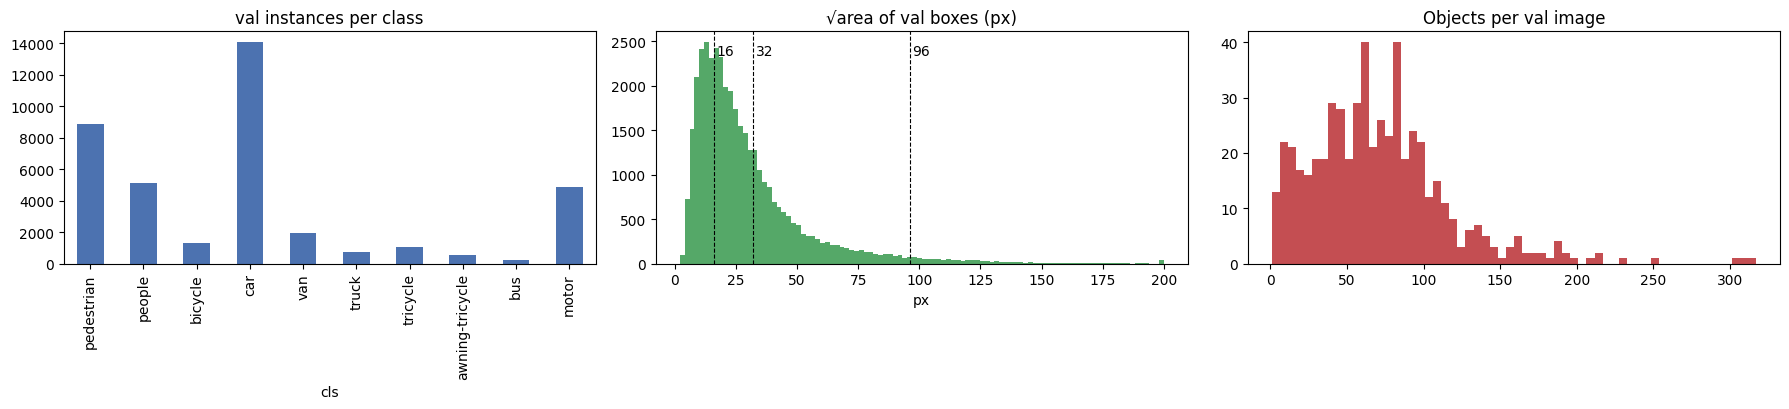

In [7]:
rows = [dict(split=s, cls=CLASSES[int(c)], w=w, h=h, img_w=r["w"], img_h=r["h"])
        for s, recs in RECS.items() for r in recs for c, x, y, w, h in r["boxes"]]
df = pd.DataFrame(rows); df["sqrt_area"] = np.sqrt(df.w * df.h)
df["size"] = pd.cut(df.sqrt_area, [0, 16, 32, 96, 1e9], labels=["tiny <16", "small 16-32", "medium 32-96", "large >96"])

size_tab = (pd.crosstab(df.split, df["size"], normalize="index") * 100).round(1)
print("Object-size distribution (% of boxes, COCO area convention):"); display(size_tab)
EDA_SPLIT = "train" if "train" in RECS else "val"
print(f"Image resolutions ({EDA_SPLIT}):"); display(pd.Series([f'{r["w"]}x{r["h"]}' for r in RECS[EDA_SPLIT]]).value_counts().head(6))

fig, ax = plt.subplots(1, 3, figsize=(18, 4.2))
df[df.split == EDA_SPLIT].cls.value_counts().reindex(CLASSES).plot.bar(ax=ax[0], color="#4C72B0"); ax[0].set_title(f"{EDA_SPLIT} instances per class")
ax[1].hist(df[df.split == EDA_SPLIT].sqrt_area.clip(upper=200), bins=100, color="#55A868")
for v, l in [(16, "16"), (32, "32"), (96, "96")]: ax[1].axvline(v, ls="--", c="k", lw=0.8); ax[1].text(v + 1, ax[1].get_ylim()[1] * 0.9, l)
ax[1].set_title(f"√area of {EDA_SPLIT} boxes (px)"); ax[1].set_xlabel("px")
ax[2].hist([len(r["boxes"]) for r in RECS[EDA_SPLIT]], bins=60, color="#C44E52"); ax[2].set_title(f"Objects per {EDA_SPLIT} image")
plt.tight_layout(); plt.savefig(OUT / "eda.png", dpi=130); plt.show()

## 3 · Build YOLO datasets
* **Full-image set** (baseline): original images with ignore regions greyed out.
* **Slice set** (SF): overlapping `TILE×TILE` crops at original resolution + the full images.
  A box is kept in a tile if ≥ `MIN_BOX_VISIBILITY` of its area is inside; most empty tiles are dropped (a few kept as negatives).

In [8]:
YOLO_ROOT = DATA / "yolo"

def masked_image(r):
    img = cv2.imread(str(r["file"]))
    if MASK_IGNORE:
        for x, y, w, h in r["ignore"].astype(int): img[max(y, 0):y + h, max(x, 0):x + w] = 114
    return img

def yolo_lines(boxes, W, H):
    return "".join(f"{int(c)} {(x + w / 2) / W:.6f} {(y + h / 2) / H:.6f} {w / W:.6f} {h / H:.6f}\n" for c, x, y, w, h in boxes)

def write_full(r, split):
    im_p = YOLO_ROOT / "images" / f"{split}_full" / f"{r['stem']}.jpg"
    lb_p = YOLO_ROOT / "labels" / f"{split}_full" / f"{r['stem']}.txt"
    if not im_p.exists():
        if MASK_IGNORE and len(r["ignore"]): cv2.imwrite(str(im_p), masked_image(r), [cv2.IMWRITE_JPEG_QUALITY, 95])
        else: os.symlink(r["file"], im_p)
    lb_p.write_text(yolo_lines(r["boxes"], r["w"], r["h"]))
    return 1

def write_tiles(r, split):
    img = masked_image(r); H, W = img.shape[:2]
    rng = random.Random(f"{SEED}-{r['stem']}"); n = 0
    b = r["boxes"]; x1, y1 = b[:, 1], b[:, 2]; x2, y2 = x1 + b[:, 3], y1 + b[:, 4]; area = b[:, 3] * b[:, 4]
    for tx1, ty1, tx2, ty2 in get_slice_bboxes(H, W, TILE, TILE, False, TILE_OVERLAP, TILE_OVERLAP):
        cx1, cy1 = np.clip(x1, tx1, tx2), np.clip(y1, ty1, ty2)
        cx2, cy2 = np.clip(x2, tx1, tx2), np.clip(y2, ty1, ty2)
        cw, ch = cx2 - cx1, cy2 - cy1
        keep = (cw >= MIN_BOX_SIDE) & (ch >= MIN_BOX_SIDE) & (cw * ch >= MIN_BOX_VISIBILITY * area)
        if not keep.any() and rng.random() > EMPTY_TILE_KEEP: continue
        tw, th = tx2 - tx1, ty2 - ty1
        tb = np.stack([b[keep, 0], cx1[keep] - tx1, cy1[keep] - ty1, cw[keep], ch[keep]], 1)
        name = f"{r['stem']}_{tx1}_{ty1}"
        cv2.imwrite(str(YOLO_ROOT / "images" / f"{split}_tiles" / f"{name}.jpg"), img[ty1:ty2, tx1:tx2], [cv2.IMWRITE_JPEG_QUALITY, 95])
        (YOLO_ROOT / "labels" / f"{split}_tiles" / f"{name}.txt").write_text(yolo_lines(tb, tw, th)); n += 1
    return n

def build(split, kind):
    for d in ("images", "labels"):
        p = YOLO_ROOT / d / f"{split}_{kind}"
        if p.exists() and d == "images" and FORCE_REBUILD: shutil.rmtree(p)
        p.mkdir(parents=True, exist_ok=True)
    done = YOLO_ROOT / f".{split}_{kind}.done"
    if done.exists(): return len(list((YOLO_ROOT / "images" / f"{split}_{kind}").glob("*.jpg")))
    fn = write_full if kind == "full" else write_tiles
    with ThreadPoolExecutor(WORKERS) as ex:     # cv2 releases the GIL → threads scale well
        n = sum(tqdm(ex.map(lambda r: fn(r, split), RECS[split]), total=len(RECS[split]), desc=f"{split}_{kind}"))
    done.touch(); return n

FORCE_REBUILD = False
def write_yaml(name, train, val):
    y = dict(path=str(YOLO_ROOT), train=train, val=val, names=dict(enumerate(CLASSES)))
    p = DATA / f"{name}.yaml"; yaml.safe_dump(y, open(p, "w"), sort_keys=False); return p

if EVAL_ONLY:
    DATA_BASE = DATA_SF = None; print("EVAL_ONLY: training sets not built")
else:
    counts = {f"{s}_{k}": build(s, k) for s in ("train", "val") for k in ("full", "tiles")}
    print(counts)

    DATA_BASE = write_yaml("visdrone_full",  "images/train_full", "images/val_full")
    DATA_SF   = write_yaml("visdrone_sahi_sf", ["images/train_tiles"] + (["images/train_full"] if SF_INCLUDE_FULL else []), "images/val_tiles")
    print(open(DATA_SF).read())

EVAL_ONLY: training sets not built


In [9]:
# Visual sanity check of generated tiles + labels (skipped in EVAL_ONLY mode)
tiles = sorted((YOLO_ROOT / "images" / "train_tiles").glob("*.jpg"))
if not tiles: print("no train tiles in this run (EVAL_ONLY)")
fig, axes = plt.subplots(1, 4, figsize=(20, 5)) if tiles else (None, [])
for ax, f in zip(axes, random.Random(SEED).sample(tiles, min(4, len(tiles)))):
    im = cv2.cvtColor(cv2.imread(str(f)), cv2.COLOR_BGR2RGB); h, w = im.shape[:2]
    for ln in (YOLO_ROOT / "labels" / "train_tiles" / f"{f.stem}.txt").read_text().splitlines():
        c, xc, yc, bw, bh = map(float, ln.split())
        cv2.rectangle(im, (int((xc - bw / 2) * w), int((yc - bh / 2) * h)), (int((xc + bw / 2) * w), int((yc + bh / 2) * h)),
                      tuple(int(v) for v in plt.cm.tab10(int(c))[:3][::-1] * np.array(255)), 1)
    ax.imshow(im); ax.set_title(f.stem, fontsize=8); ax.axis("off")
if tiles: plt.tight_layout(); plt.savefig(OUT / "tiles_sanity.png", dpi=110); plt.show()

no train tiles in this run (EVAL_ONLY)


## 4 · Training YOLO26
Both models start from the same COCO-pretrained YOLO26 checkpoint and use identical hyper-parameters; only the data differ.

| Run | Train data | Purpose |
|---|---|---|
| `base_fullimg` | 6 471 full images | conventional baseline |
| `sf_tiles` | tiles + full images | **slice-aided fine-tuning** (SAHI-SF) |

Augmentation: mosaic (closed for last 10 epochs), HSV, scale 0.5, h-flip. No rotation (aerial nadir-ish views keep "up" meaningful for vehicles/people).

In [10]:
HYP = dict(imgsz=IMGSZ, batch=BATCH, device=TRAIN_DEVICE, workers=WORKERS, seed=SEED, deterministic=False,
           optimizer="auto", cos_lr=True, close_mosaic=10, mosaic=1.0, mixup=0.0, copy_paste=0.0,
           degrees=0.0, scale=0.5, fliplr=0.5, amp=True, cache=False, plots=True,
           project=str(RUNS), exist_ok=True, verbose=False)

def train(name, data, epochs):
    run = RUNS / name; best, last, done = run / "weights" / "best.pt", run / "weights" / "last.pt", run / "DONE"
    if done.exists() and best.exists():
        print(f"[{name}] already trained → {best}"); return best
    t0 = time.time()
    if last.exists():
        print(f"[{name}] resuming from {last}"); YOLO(str(last)).train(resume=True)
    else:
        YOLO(MODEL_WEIGHTS).train(data=str(data), name=name, epochs=epochs, patience=PATIENCE, **HYP)
    done.write_text(f"{(time.time() - t0) / 3600:.2f} h"); print(f"[{name}] finished in {done.read_text()}")
    return best

W = {}
if TRAIN_BASELINE or "base" in HAVE:
    W["base"] = train("base_fullimg", DATA_BASE, EPOCHS_BASE)
W["sf"] = train("sf_tiles", DATA_SF, EPOCHS_SF)
W

[base_fullimg] already trained → /kaggle/working/runs/base_fullimg/weights/best.pt
[sf_tiles] already trained → /kaggle/working/runs/sf_tiles/weights/best.pt


{'base': PosixPath('/kaggle/working/runs/base_fullimg/weights/best.pt'),
 'sf': PosixPath('/kaggle/working/runs/sf_tiles/weights/best.pt')}

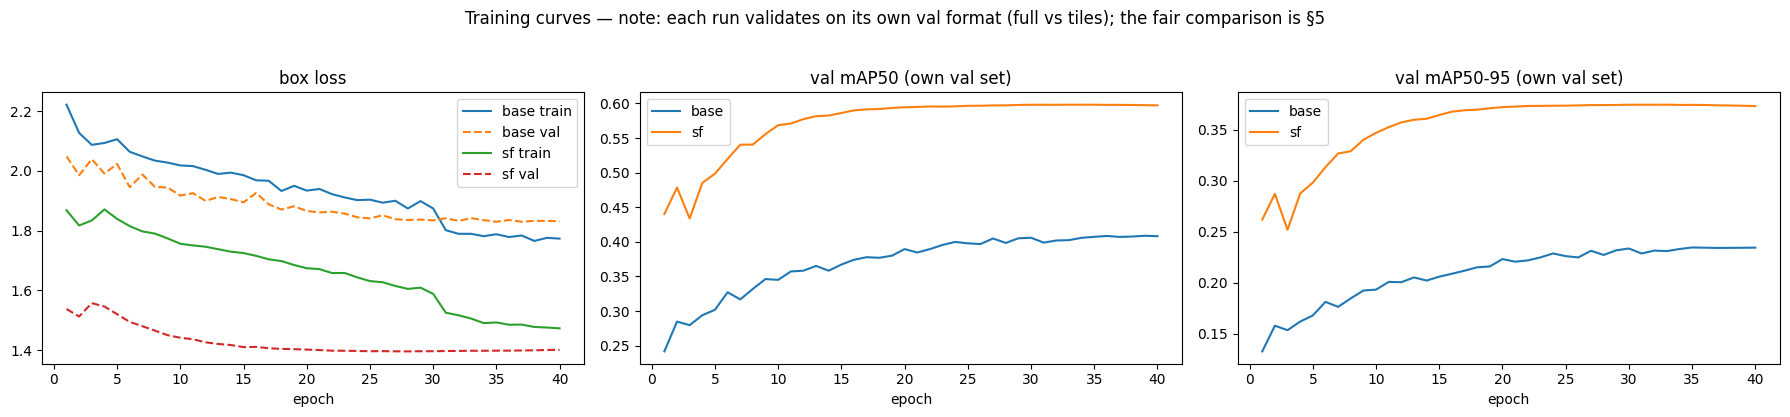

In [11]:
fig, ax = plt.subplots(1, 3, figsize=(18, 4))
for key, run in [("base", "base_fullimg"), ("sf", "sf_tiles")]:
    f = RUNS / run / "results.csv"
    if not f.exists(): continue
    r = pd.read_csv(f); r.columns = [c.strip() for c in r.columns]
    ax[0].plot(r.epoch, r["train/box_loss"], label=f"{key} train"); ax[0].plot(r.epoch, r["val/box_loss"], "--", label=f"{key} val")
    ax[1].plot(r.epoch, r["metrics/mAP50(B)"], label=key); ax[2].plot(r.epoch, r["metrics/mAP50-95(B)"], label=key)
for a, t in zip(ax, ["box loss", "val mAP50 (own val set)", "val mAP50-95 (own val set)"]): a.set_title(t); a.legend(); a.set_xlabel("epoch")
plt.suptitle("Training curves — note: each run validates on its own val format (full vs tiles); the fair comparison is §5", y=1.03)
plt.tight_layout(); plt.savefig(OUT / "training_curves.png", dpi=120, bbox_inches="tight"); plt.show()

## 5 · Unified evaluation harness
Every method outputs detections in **original-image coordinates** and is scored by the same COCO evaluator
(ignore regions as crowd, `maxDets=500`, extra **tiny** size bucket).

In [12]:
AREA_RNG = {"all": [0, 1e10], "tiny": [0, 16 ** 2], "small": [0, 32 ** 2], "medium": [32 ** 2, 96 ** 2], "large": [96 ** 2, 1e10]}

def coco_eval(split, dets):
    gt = COCO_GT[split]
    if not dets: return {k: 0.0 for k in ["AP", "AP50", "AP75", "AP_tiny", "AP_s", "AP_m", "AP_l", "AR500"]}, np.zeros(len(CLASSES))
    with contextlib.redirect_stdout(io.StringIO()):
        dt = gt.loadRes(dets); E = COCOeval(gt, dt, "bbox")
        E.params.maxDets = [1, 100, MAX_DETS]
        E.params.areaRng, E.params.areaRngLbl = list(AREA_RNG.values()), list(AREA_RNG.keys())
        E.evaluate(); E.accumulate()
    P, R = E.eval["precision"], E.eval["recall"]       # P: [T,R,K,A,M]  R: [T,K,A,M]
    def ap(area="all", t=None, k=slice(None)):
        a = E.params.areaRngLbl.index(area); p = P[:, :, k, a, -1] if t is None else P[[t], :, k, a, -1]
        p = p[p > -1]; return float(p.mean()) if p.size else float("nan")
    r = R[:, :, 0, -1]; r = r[r > -1]
    m = dict(AP=ap(), AP50=ap(t=0), AP75=ap(t=5), AP_tiny=ap("tiny"), AP_s=ap("small"), AP_m=ap("medium"),
             AP_l=ap("large"), AR500=float(r.mean()) if r.size else float("nan"))
    per_cls = np.array([ap(k=k) for k in range(len(CLASSES))])
    return m, per_cls

_YOLO_CACHE = {}
def predict_full(weights, split, imgsz):
    model = _YOLO_CACHE.setdefault(str(weights), YOLO(str(weights)))
    recs = RECS[split]; dets, times = [], []
    model.predict(str(recs[0]["file"]), imgsz=imgsz, device=DEVICE, verbose=False)          # warm-up
    for r in tqdm(recs, desc=f"FI@{imgsz}", leave=False):
        if N_GPU: torch.cuda.synchronize()
        t0 = time.perf_counter()
        res = model.predict(str(r["file"]), imgsz=imgsz, conf=EVAL_CONF, max_det=MAX_DETS, device=DEVICE, verbose=False)[0]
        if N_GPU: torch.cuda.synchronize()
        times.append(time.perf_counter() - t0)
        b = res.boxes
        for (x1, y1, x2, y2), s, c in zip(b.xyxy.cpu().numpy(), b.conf.cpu().numpy(), b.cls.cpu().numpy()):
            dets.append(dict(image_id=r["id"], category_id=int(c) + 1, bbox=[float(x1), float(y1), float(x2 - x1), float(y2 - y1)], score=float(s)))
    return dets, 1000 * float(np.mean(times))

_SAHI_CACHE = {}
def sahi_model(weights, conf=EVAL_CONF, image_size=IMGSZ):
    key = (str(weights), conf, image_size)
    if key not in _SAHI_CACHE:
        _SAHI_CACHE[key] = AutoDetectionModel.from_pretrained(model_type="ultralytics", model_path=str(weights),
                                                              confidence_threshold=conf, device=SAHI_DEVICE, image_size=image_size)
    return _SAHI_CACHE[key]

def run_sahi(model, image, slice_=640, overlap=0.2, fi=True, pp="NMS", metric="IOU", thr=0.5):
    return get_sliced_prediction(image, model, slice_height=slice_, slice_width=slice_, overlap_height_ratio=overlap,
                                 overlap_width_ratio=overlap, perform_standard_pred=fi, postprocess_type=pp,
                                 postprocess_match_metric=metric, postprocess_match_threshold=thr,
                                 postprocess_class_agnostic=False, verbose=0, batch_size=SAHI_BATCH,
                                 force_postprocess_type=True)   # use exactly the merge we ask for (SAHI otherwise swaps to NMS when conf<0.1)

def predict_sahi(weights, split, **cfg):
    model = sahi_model(weights); recs = RECS[split]; dets, times = [], []
    run_sahi(model, str(recs[0]["file"]), **cfg)                                             # warm-up
    for r in tqdm(recs, desc="SAHI", leave=False):
        if N_GPU: torch.cuda.synchronize()
        t0 = time.perf_counter(); res = run_sahi(model, str(r["file"]), **cfg)
        if N_GPU: torch.cuda.synchronize()
        times.append(time.perf_counter() - t0)
        preds = sorted(res.object_prediction_list, key=lambda p: -p.score.value)[:MAX_DETS]
        for p in preds:
            bb = p.bbox
            dets.append(dict(image_id=r["id"], category_id=int(p.category.id) + 1,
                             bbox=[float(bb.minx), float(bb.miny), float(bb.maxx - bb.minx), float(bb.maxy - bb.miny)], score=float(p.score.value)))
    return dets, 1000 * float(np.mean(times))

import torchvision

def fuse_nms(arrays, iou=0.5, max_det=MAX_DETS):
    # Class-wise NMS over the union of several detection sets. Rows: [image_id, category_id, x, y, w, h, score]
    a = np.concatenate([x for x in arrays if len(x)], 0) if any(len(x) for x in arrays) else np.zeros((0, 7), np.float32)
    out = []
    for iid in np.unique(a[:, 0]):
        d = a[a[:, 0] == iid]; t = torch.from_numpy(d)
        boxes = torch.cat([t[:, 2:4], t[:, 2:4] + t[:, 4:6]], 1)
        keep = torchvision.ops.batched_nms(boxes, t[:, 6], t[:, 1].long(), iou)[:max_det]   # sorted by score
        out.append(d[keep.numpy()])
    return np.concatenate(out, 0) if out else a

def to_dets(a):
    return [dict(image_id=int(r[0]), category_id=int(r[1]), bbox=[float(v) for v in r[2:6]], score=float(r[6])) for r in a]

PRED_CACHE = {}   # compact numpy arrays: [image_id, category_id, x, y, w, h, score]
LAT_CACHE  = {}   # (name, split) → ms / image
CFG_BY_NAME = {}  # filled by the ablation cell; lets hybrid rows reference their parts by name

def evaluate(cfg, split, quiet=False):
    cfg = dict(cfg); name, kind, w = cfg.pop("name"), cfg.pop("kind"), cfg.pop("w")
    if w not in W: return None
    if kind == "hybrid":        # re-uses cached component predictions → no extra inference
        for part in cfg["parts"]:
            if (part, split) not in PRED_CACHE: evaluate(CFG_BY_NAME[part], split, quiet=True)
        t0 = time.perf_counter()
        arr = fuse_nms([PRED_CACHE[(p, split)] for p in cfg["parts"]], cfg.get("iou", 0.5))
        ms = sum(LAT_CACHE[(p, split)] for p in cfg["parts"]) + 1000 * (time.perf_counter() - t0) / len(RECS[split])
        dets = to_dets(arr)
    else:
        dets, ms = predict_full(W[w], split, cfg["imgsz"]) if kind == "full" else predict_sahi(W[w], split, **cfg)
        arr = np.array([[d["image_id"], d["category_id"], *d["bbox"], d["score"]] for d in dets], np.float32).reshape(-1, 7)
    PRED_CACHE[(name, split)], LAT_CACHE[(name, split)] = arr, ms
    if quiet: return None
    m, per_cls = coco_eval(split, dets)
    print(f"{name:<48s} AP={m['AP']:.4f} AP50={m['AP50']:.4f} AP_tiny={m['AP_tiny']:.4f}  {ms:.1f} ms/img")
    return dict(method=name, **m, ms_per_img=ms, dets_per_img=len(dets) / len(RECS[split])), per_cls

## 6 · Ablation study on **val**
Rows follow the SAHI paper (FI / SF / SAHI / FI+SAHI / SF+SAHI+FI / overlap) and extend it with
slice-size (zoom), merge algorithm and match-metric studies. **The best row is selected here, on val only.**

In [13]:
S = dict(slice_=640, overlap=0.2, fi=True, pp="NMS", metric="IOU", thr=0.5)   # v2 SAHI default (v1 used GREEDYNMM/IOS)
def sahi_cfg(name, w="sf", **kw): return dict(name=name, kind="sahi", w=w, **{**S, **kw})
def full_cfg(name, w="sf", imgsz=640): return dict(name=name, kind="full", w=w, imgsz=imgsz)
def hybrid(name, *parts, iou=0.5): return dict(name=name, kind="hybrid", w="sf", parts=list(parts), iou=iou)

ABLATION = [
    # ---- conventional training (reference) ----------------------------------
    full_cfg("BASE · FI@640",   w="base", imgsz=640),
    full_cfg("BASE · FI@1280",  w="base", imgsz=1280),
    full_cfg("BASE · FI@1536",  w="base", imgsz=1536),
    sahi_cfg("BASE · SAHI 640 (no FI)", w="base", fi=False),
    # ---- SF model, full-image inference at increasing resolution ------------
    full_cfg("SF · FI@640",  imgsz=640),
    full_cfg("SF · FI@1280", imgsz=1280),
    full_cfg("SF · FI@1536", imgsz=1536),
    full_cfg("SF · FI@1920", imgsz=1920),
    # ---- SF model, SAHI -----------------------------------------------------
    sahi_cfg("SF · SAHI + FI  [v1 default: GREEDYNMM-IOS]", pp="GREEDYNMM", metric="IOS"),
    sahi_cfg("SF · SAHI + FI  [default]"),                                    # NMS-IOU 0.5, SAHI's internal FI @640
    sahi_cfg("SF · SAHI 640 (no FI)",       fi=False),
    sahi_cfg("SF · SAHI 512 (no FI)",       fi=False, slice_=512),
    sahi_cfg("SF · SAHI 448 (no FI)",       fi=False, slice_=448),
    # ---- hybrid: slices + high-resolution full-image pass, class-wise NMS ----
    hybrid("SF · SAHI 640 ⊕ FI@1280",          "SF · SAHI 640 (no FI)", "SF · FI@1280"),
    hybrid("SF · SAHI 512 ⊕ FI@1280",          "SF · SAHI 512 (no FI)", "SF · FI@1280"),
    hybrid("SF · SAHI 448 ⊕ FI@1280",          "SF · SAHI 448 (no FI)", "SF · FI@1280"),
    hybrid("SF · SAHI 512 ⊕ FI@1536",          "SF · SAHI 512 (no FI)", "SF · FI@1536"),
    hybrid("SF · SAHI 448 ⊕ FI@1536",          "SF · SAHI 448 (no FI)", "SF · FI@1536"),
    hybrid("SF · SAHI 512 ⊕ FI@1280 · IoU 0.6", "SF · SAHI 512 (no FI)", "SF · FI@1280", iou=0.6),
    hybrid("SF · SAHI 512 ⊕ FI@1280 · IoU 0.7", "SF · SAHI 512 (no FI)", "SF · FI@1280", iou=0.7),
    hybrid("SF · FI@1280 ⊕ FI@1920",           "SF · FI@1280", "SF · FI@1920"),
    hybrid("SF · SAHI 512 ⊕ FI@1280 ⊕ FI@1920", "SF · SAHI 512 (no FI)", "SF · FI@1280", "SF · FI@1920"),
]
if FAST_DEV_RUN:
    keep = {"BASE · FI@640", "SF · FI@640", "SF · FI@1280", "SF · SAHI + FI  [default]", "SF · SAHI 512 (no FI)", "SF · SAHI 512 ⊕ FI@1280"}
    ABLATION = [c for c in ABLATION if c["name"] in keep]
CFG_BY_NAME.update({c["name"]: c for c in ABLATION})

val_rows, val_cls = [], {}
for cfg in ABLATION:
    out = evaluate(cfg, "val")
    if out: val_rows.append(out[0]); val_cls[cfg["name"]] = out[1]
VAL = pd.DataFrame(val_rows).set_index("method")
VAL.to_csv(OUT / "ablation_val.csv")
VAL.style.format("{:.4f}", subset=[c for c in VAL.columns if c.startswith("A")]).format("{:.1f}", subset=["ms_per_img", "dets_per_img"]) \
   .background_gradient(cmap="Greens", subset=["AP", "AP50", "AP_tiny", "AP_s"])

FI@640:   0%|          | 0/548 [00:00<?, ?it/s]

BASE · FI@640                                    AP=0.2163 AP50=0.3663 AP_tiny=0.0610  20.9 ms/img


FI@1280:   0%|          | 0/548 [00:00<?, ?it/s]

BASE · FI@1280                                   AP=0.2794 AP50=0.4682 AP_tiny=0.1263  29.5 ms/img


FI@1536:   0%|          | 0/548 [00:00<?, ?it/s]

BASE · FI@1536                                   AP=0.2732 AP50=0.4648 AP_tiny=0.1357  41.2 ms/img


... (17 outputs left out)

SF · SAHI 512 (no FI)                            AP=0.3420 AP50=0.5638 AP_tiny=0.1783  137.0 ms/img


SAHI:   0%|          | 0/548 [00:00<?, ?it/s]

SF · SAHI 448 (no FI)                            AP=0.3484 AP50=0.5705 AP_tiny=0.1816  132.5 ms/img
SF · SAHI 640 ⊕ FI@1280                          AP=0.3448 AP50=0.5615 AP_tiny=0.1634  131.3 ms/img
SF · SAHI 512 ⊕ FI@1280                          AP=0.3508 AP50=0.5711 AP_tiny=0.1789  170.2 ms/img
SF · SAHI 448 ⊕ FI@1280                          AP=0.3573 AP50=0.5789 AP_tiny=0.1826  165.7 ms/img
SF · SAHI 512 ⊕ FI@1536                          AP=0.3516 AP50=0.5748 AP_tiny=0.1834  183.0 ms/img
SF · SAHI 448 ⊕ FI@1536                          AP=0.3580 AP50=0.5807 AP_tiny=0.1869  178.4 ms/img
SF · SAHI 512 ⊕ FI@1280 · IoU 0.6                AP=0.3518 AP50=0.5703 AP_tiny=0.1795  170.1 ms/img
SF · SAHI 512 ⊕ FI@1280 · IoU 0.7                AP=0.3512 AP50=0.5648 AP_tiny=0.1796  170.3 ms/img
SF · FI@1280 ⊕ FI@1920                           AP=0.3713 AP50=0.5925 AP_tiny=0.1872  96.7 ms/img
SF · SAHI 512 ⊕ FI@1280 ⊕ FI@1920                AP=0.3610 AP50=0.5839 AP_tiny=0.1923  234.8 ms/img


,AP,AP50,AP75,AP_tiny,AP_s,AP_m,AP_l,AR500,ms_per_img,dets_per_img
method,,,,,,,,,,
BASE · FI@640,0.2163,0.3663,0.2142,0.0610,0.1240,0.3213,0.5110,0.3079,20.9,241.8
BASE · FI@1280,0.2794,0.4682,0.2812,0.1263,0.2023,0.3733,0.4152,0.4086,29.5,295.0
BASE · FI@1536,0.2732,0.4648,0.2740,0.1357,0.2065,0.3575,0.3437,0.4113,41.2,309.6
BASE · SAHI 640 (no FI),0.2465,0.4318,0.2420,0.1086,0.1794,0.3316,0.3254,0.3861,105.3,286.2
SF · FI@640,0.2390,0.3968,0.2385,0.0687,0.1399,0.3610,0.6118,0.3219,20.8,220.8
SF · FI@1280,0.3463,0.5506,0.3579,0.1554,0.2563,0.4684,0.5605,0.4540,31.3,238.3
SF · FI@1536,0.3570,0.5693,0.3706,0.1734,0.2702,0.4768,0.5436,0.4685,44.0,245.4
SF · FI@1920,0.3658,0.5803,0.3821,0.1885,0.2861,0.4768,0.5336,0.4813,63.4,253.3
SF · SAHI + FI [v1 default: GREEDYNMM-IOS],0.2436,0.4448,0.2272,0.0957,0.1701,0.3382,0.5339,0.3498,154.3,205.8


Best on val : SF · FI@1280 ⊕ FI@1920
  cfg = {'name': 'SF · FI@1280 ⊕ FI@1920', 'kind': 'hybrid', 'w': 'sf', 'parts': ['SF · FI@1280', 'SF · FI@1920'], 'iou': 0.5}
Reference   : BASE · FI@640
Δ AP  = +15.50 pts   Δ AP_tiny = +12.62 pts


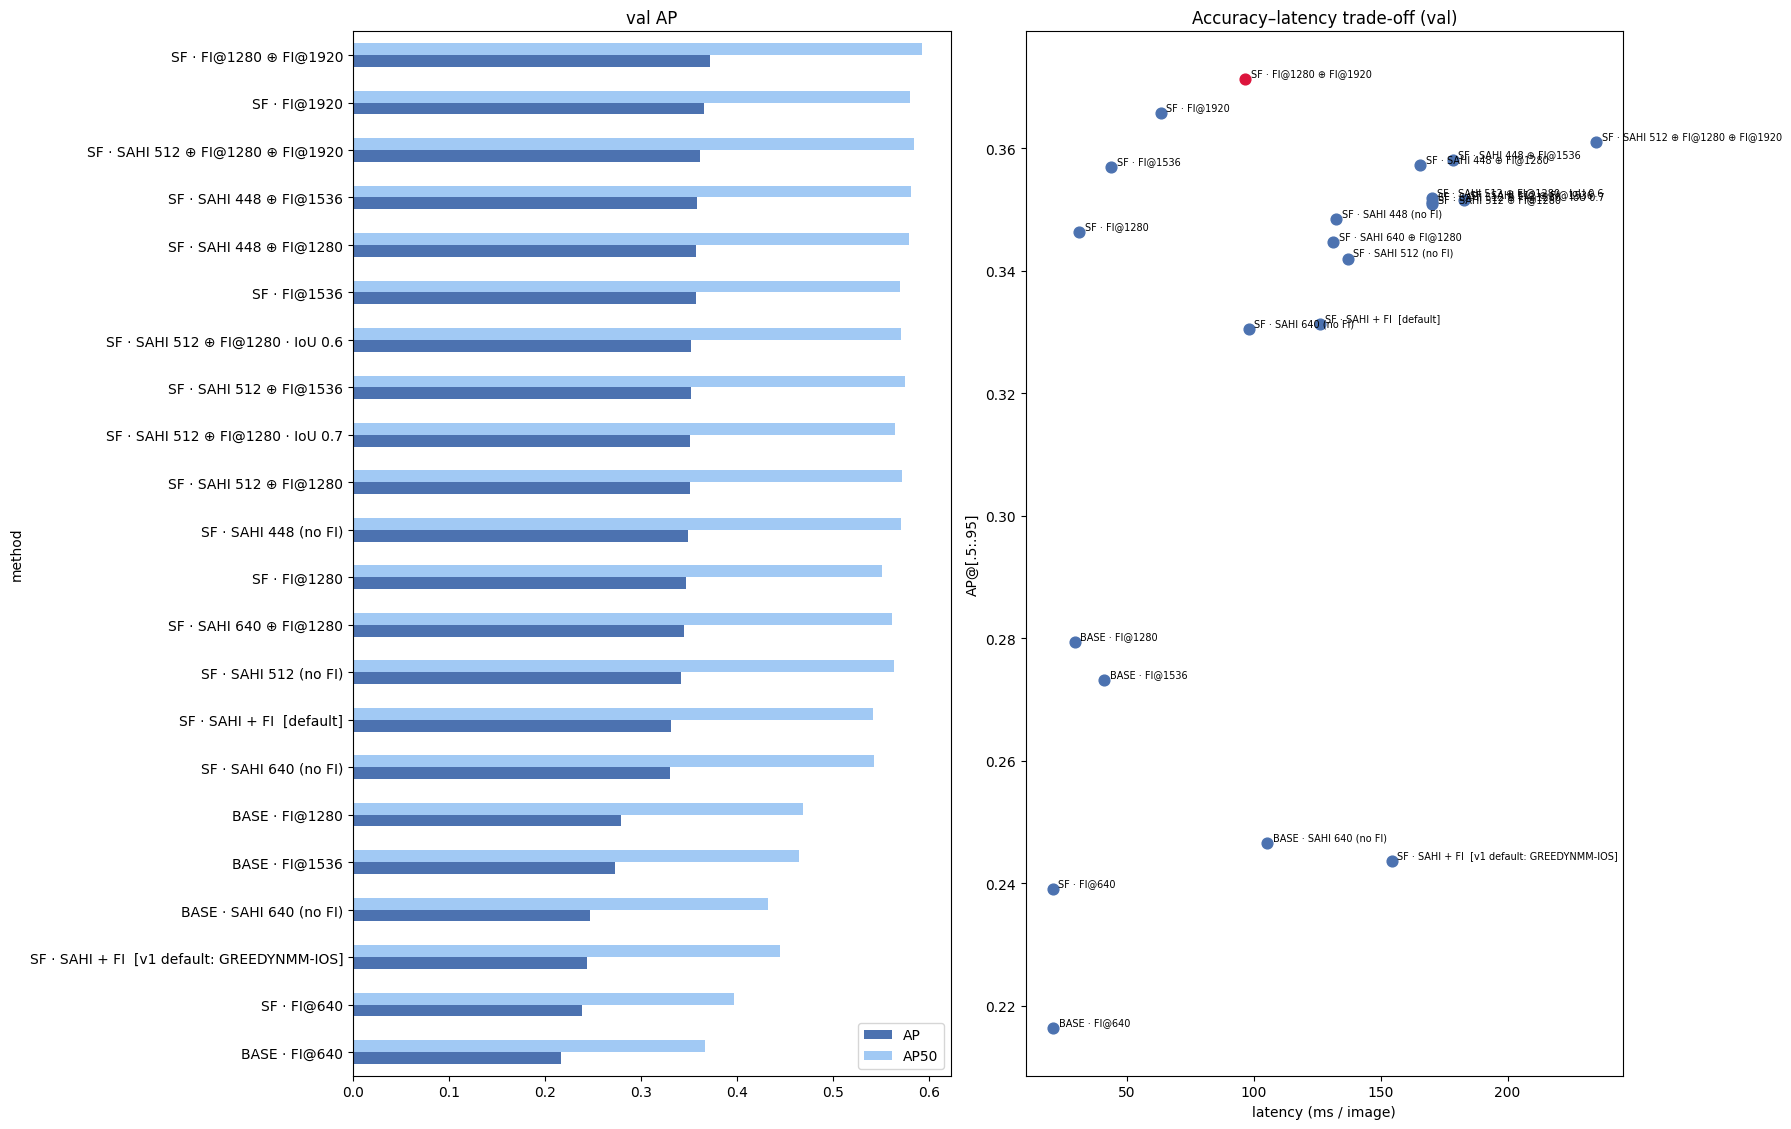

In [14]:
# Select the best configuration on val: highest AP@[.5:.95]; ties (<0.1 AP pt) broken by latency
v = VAL.sort_values("AP", ascending=False)
cands = v[v.AP >= v.AP.iloc[0] - 0.001]
BEST_NAME = cands.ms_per_img.idxmin()
BEST_CFG  = next(c for c in ABLATION if c["name"] == BEST_NAME)
REF_NAME  = "BASE · FI@640" if "BASE · FI@640" in VAL.index else "SF · FI@640"
print(f"Best on val : {BEST_NAME}\n  cfg = {BEST_CFG}")
print(f"Reference   : {REF_NAME}")
print(f"Δ AP  = {100 * (VAL.loc[BEST_NAME, 'AP'] - VAL.loc[REF_NAME, 'AP']):+.2f} pts   "
      f"Δ AP_tiny = {100 * (VAL.loc[BEST_NAME, 'AP_tiny'] - VAL.loc[REF_NAME, 'AP_tiny']):+.2f} pts")

fig, ax = plt.subplots(1, 2, figsize=(18, 0.45 * len(VAL) + 1.5))
v[["AP", "AP50"]].iloc[::-1].plot.barh(ax=ax[0], color=["#4C72B0", "#A1C9F4"]); ax[0].set_title("val AP")
for i, (n, row) in enumerate(v.iloc[::-1].iterrows()):
    ax[1].scatter(row.ms_per_img, row.AP, s=60, c="crimson" if n == BEST_NAME else "#4C72B0")
    ax[1].annotate(n, (row.ms_per_img, row.AP), fontsize=7, xytext=(4, 2), textcoords="offset points")
ax[1].set_xlabel("latency (ms / image)"); ax[1].set_ylabel("AP@[.5:.95]"); ax[1].set_title("Accuracy–latency trade-off (val)")
plt.tight_layout(); plt.savefig(OUT / "ablation_val.png", dpi=130); plt.show()

## 7 · Final report on held-out **test-dev**
Only the reference baselines and the val-selected configuration are run on test-dev — once.

In [15]:
FINAL = []
for n in dict.fromkeys(["BASE · FI@640", "BASE · FI@1280", "SF · FI@640", "SF · FI@1280", "SF · SAHI + FI  [default]", BEST_NAME]):
    c = next((c for c in ABLATION if c["name"] == n), None)
    if c is not None and c["w"] in W: FINAL.append(c)

test_rows, test_cls = [], {}
for cfg in FINAL:
    out = evaluate(cfg, "test")
    if out: test_rows.append(out[0]); test_cls[cfg["name"]] = out[1]
TEST = pd.DataFrame(test_rows).set_index("method")
TEST.to_csv(OUT / "results_testdev.csv")
TEST.style.format("{:.4f}", subset=[c for c in TEST.columns if c.startswith("A")]).format("{:.1f}", subset=["ms_per_img", "dets_per_img"]) \
    .highlight_max(color="#c6efce", subset=["AP", "AP50", "AP75", "AP_tiny", "AP_s", "AP_m", "AR500"])

FI@640:   0%|          | 0/1610 [00:00<?, ?it/s]

BASE · FI@640                                    AP=0.1774 AP50=0.3080 AP_tiny=0.0438  20.5 ms/img


FI@1280:   0%|          | 0/1610 [00:00<?, ?it/s]

BASE · FI@1280                                   AP=0.2243 AP50=0.3875 AP_tiny=0.0836  33.1 ms/img


FI@640:   0%|          | 0/1610 [00:00<?, ?it/s]

SF · FI@640                                      AP=0.1918 AP50=0.3273 AP_tiny=0.0431  20.9 ms/img


... (3 outputs left out)

SF · SAHI + FI  [default]                        AP=0.2664 AP50=0.4527 AP_tiny=0.0951  130.7 ms/img


FI@1920:   0%|          | 0/1610 [00:00<?, ?it/s]

SF · FI@1280 ⊕ FI@1920                           AP=0.2854 AP50=0.4790 AP_tiny=0.1121  103.3 ms/img


,AP,AP50,AP75,AP_tiny,AP_s,AP_m,AP_l,AR500,ms_per_img,dets_per_img
method,,,,,,,,,,
BASE · FI@640,0.1774,0.3080,0.1789,0.0438,0.0838,0.2698,0.4173,0.2752,20.5,165.8
BASE · FI@1280,0.2243,0.3875,0.2243,0.0836,0.1426,0.3123,0.3430,0.3517,33.1,186.8
SF · FI@640,0.1918,0.3273,0.1956,0.0431,0.0887,0.2973,0.5000,0.2799,20.9,142.2
SF · FI@1280,0.2684,0.4477,0.2727,0.0991,0.1644,0.3830,0.5089,0.3797,33.2,132.1
SF · SAHI + FI [default],0.2664,0.4527,0.2701,0.0951,0.1629,0.3801,0.4950,0.3937,130.7,182.4
SF · FI@1280 ⊕ FI@1920,0.2854,0.4790,0.2886,0.1121,0.1831,0.3955,0.5092,0.4068,103.3,127.2


,pedestrian,people,bicycle,car,van,truck,tricycle,awning-tricycle,bus,motor
BASE · FI@640,12.320000,4.670000,3.700000,44.410000,18.830000,24.690000,10.080000,9.550000,36.640000,12.550000
BASE · FI@1280,19.100000,7.710000,6.760000,51.700000,25.850000,29.010000,13.120000,11.340000,40.900000,18.780000
SF · FI@640,12.780000,6.400000,4.500000,45.710000,19.950000,27.020000,10.940000,12.190000,38.350000,13.960000
SF · FI@1280,20.670000,11.900000,11.040000,53.360000,29.010000,36.880000,19.360000,16.790000,46.600000,22.760000
SF · SAHI + FI [default],20.380000,11.740000,11.160000,51.780000,30.340000,34.970000,19.780000,17.930000,45.280000,23.040000
SF · FI@1280 ⊕ FI@1920,22.080000,13.320000,12.590000,54.540000,31.720000,38.510000,21.030000,18.670000,48.560000,24.390000


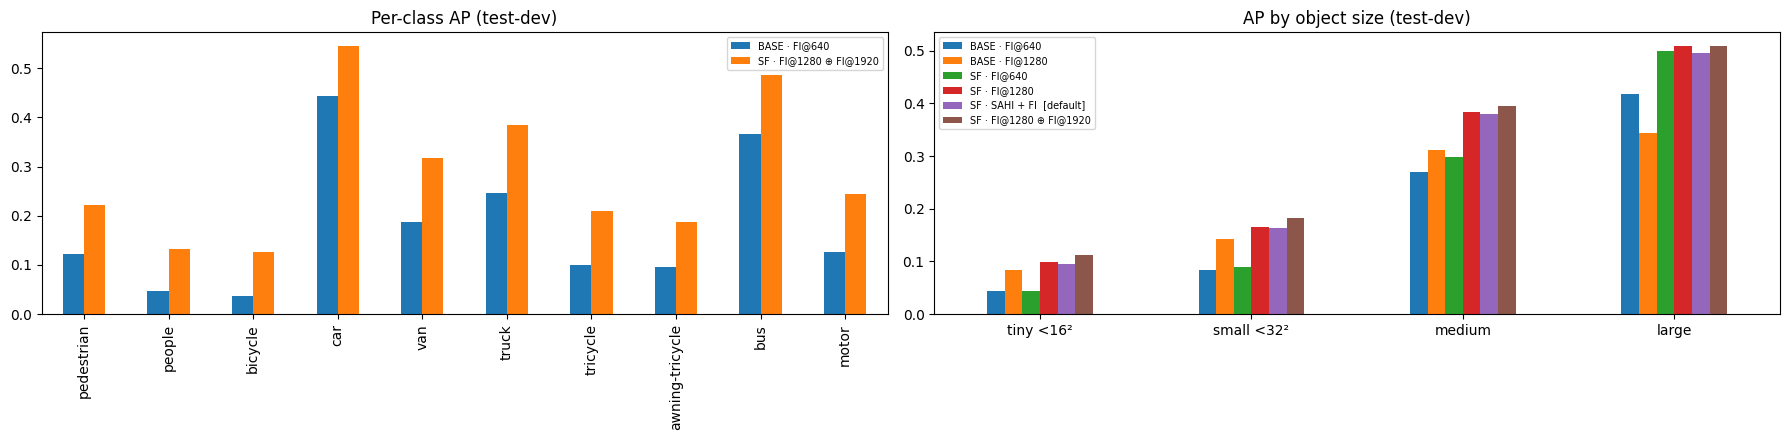

In [16]:
PC = pd.DataFrame(test_cls, index=CLASSES).T
display((PC * 100).round(2).style.background_gradient(cmap="Blues", axis=0).set_caption("test-dev per-class AP@[.5:.95] (%)"))

fig, ax = plt.subplots(1, 2, figsize=(18, 4.5))
PC.T[[c for c in dict.fromkeys([REF_NAME, BEST_NAME]) if c in PC.index]].plot.bar(ax=ax[0]); ax[0].set_title("Per-class AP (test-dev)")
TEST[["AP_tiny", "AP_s", "AP_m", "AP_l"]].T.plot.bar(ax=ax[1]); ax[1].set_title("AP by object size (test-dev)")
ax[1].set_xticklabels(["tiny <16²", "small <32²", "medium", "large"], rotation=0)
for a in ax: a.legend(fontsize=7)
plt.tight_layout(); plt.savefig(OUT / "testdev_breakdown.png", dpi=130); plt.show()

## 8 · Qualitative comparison (val)

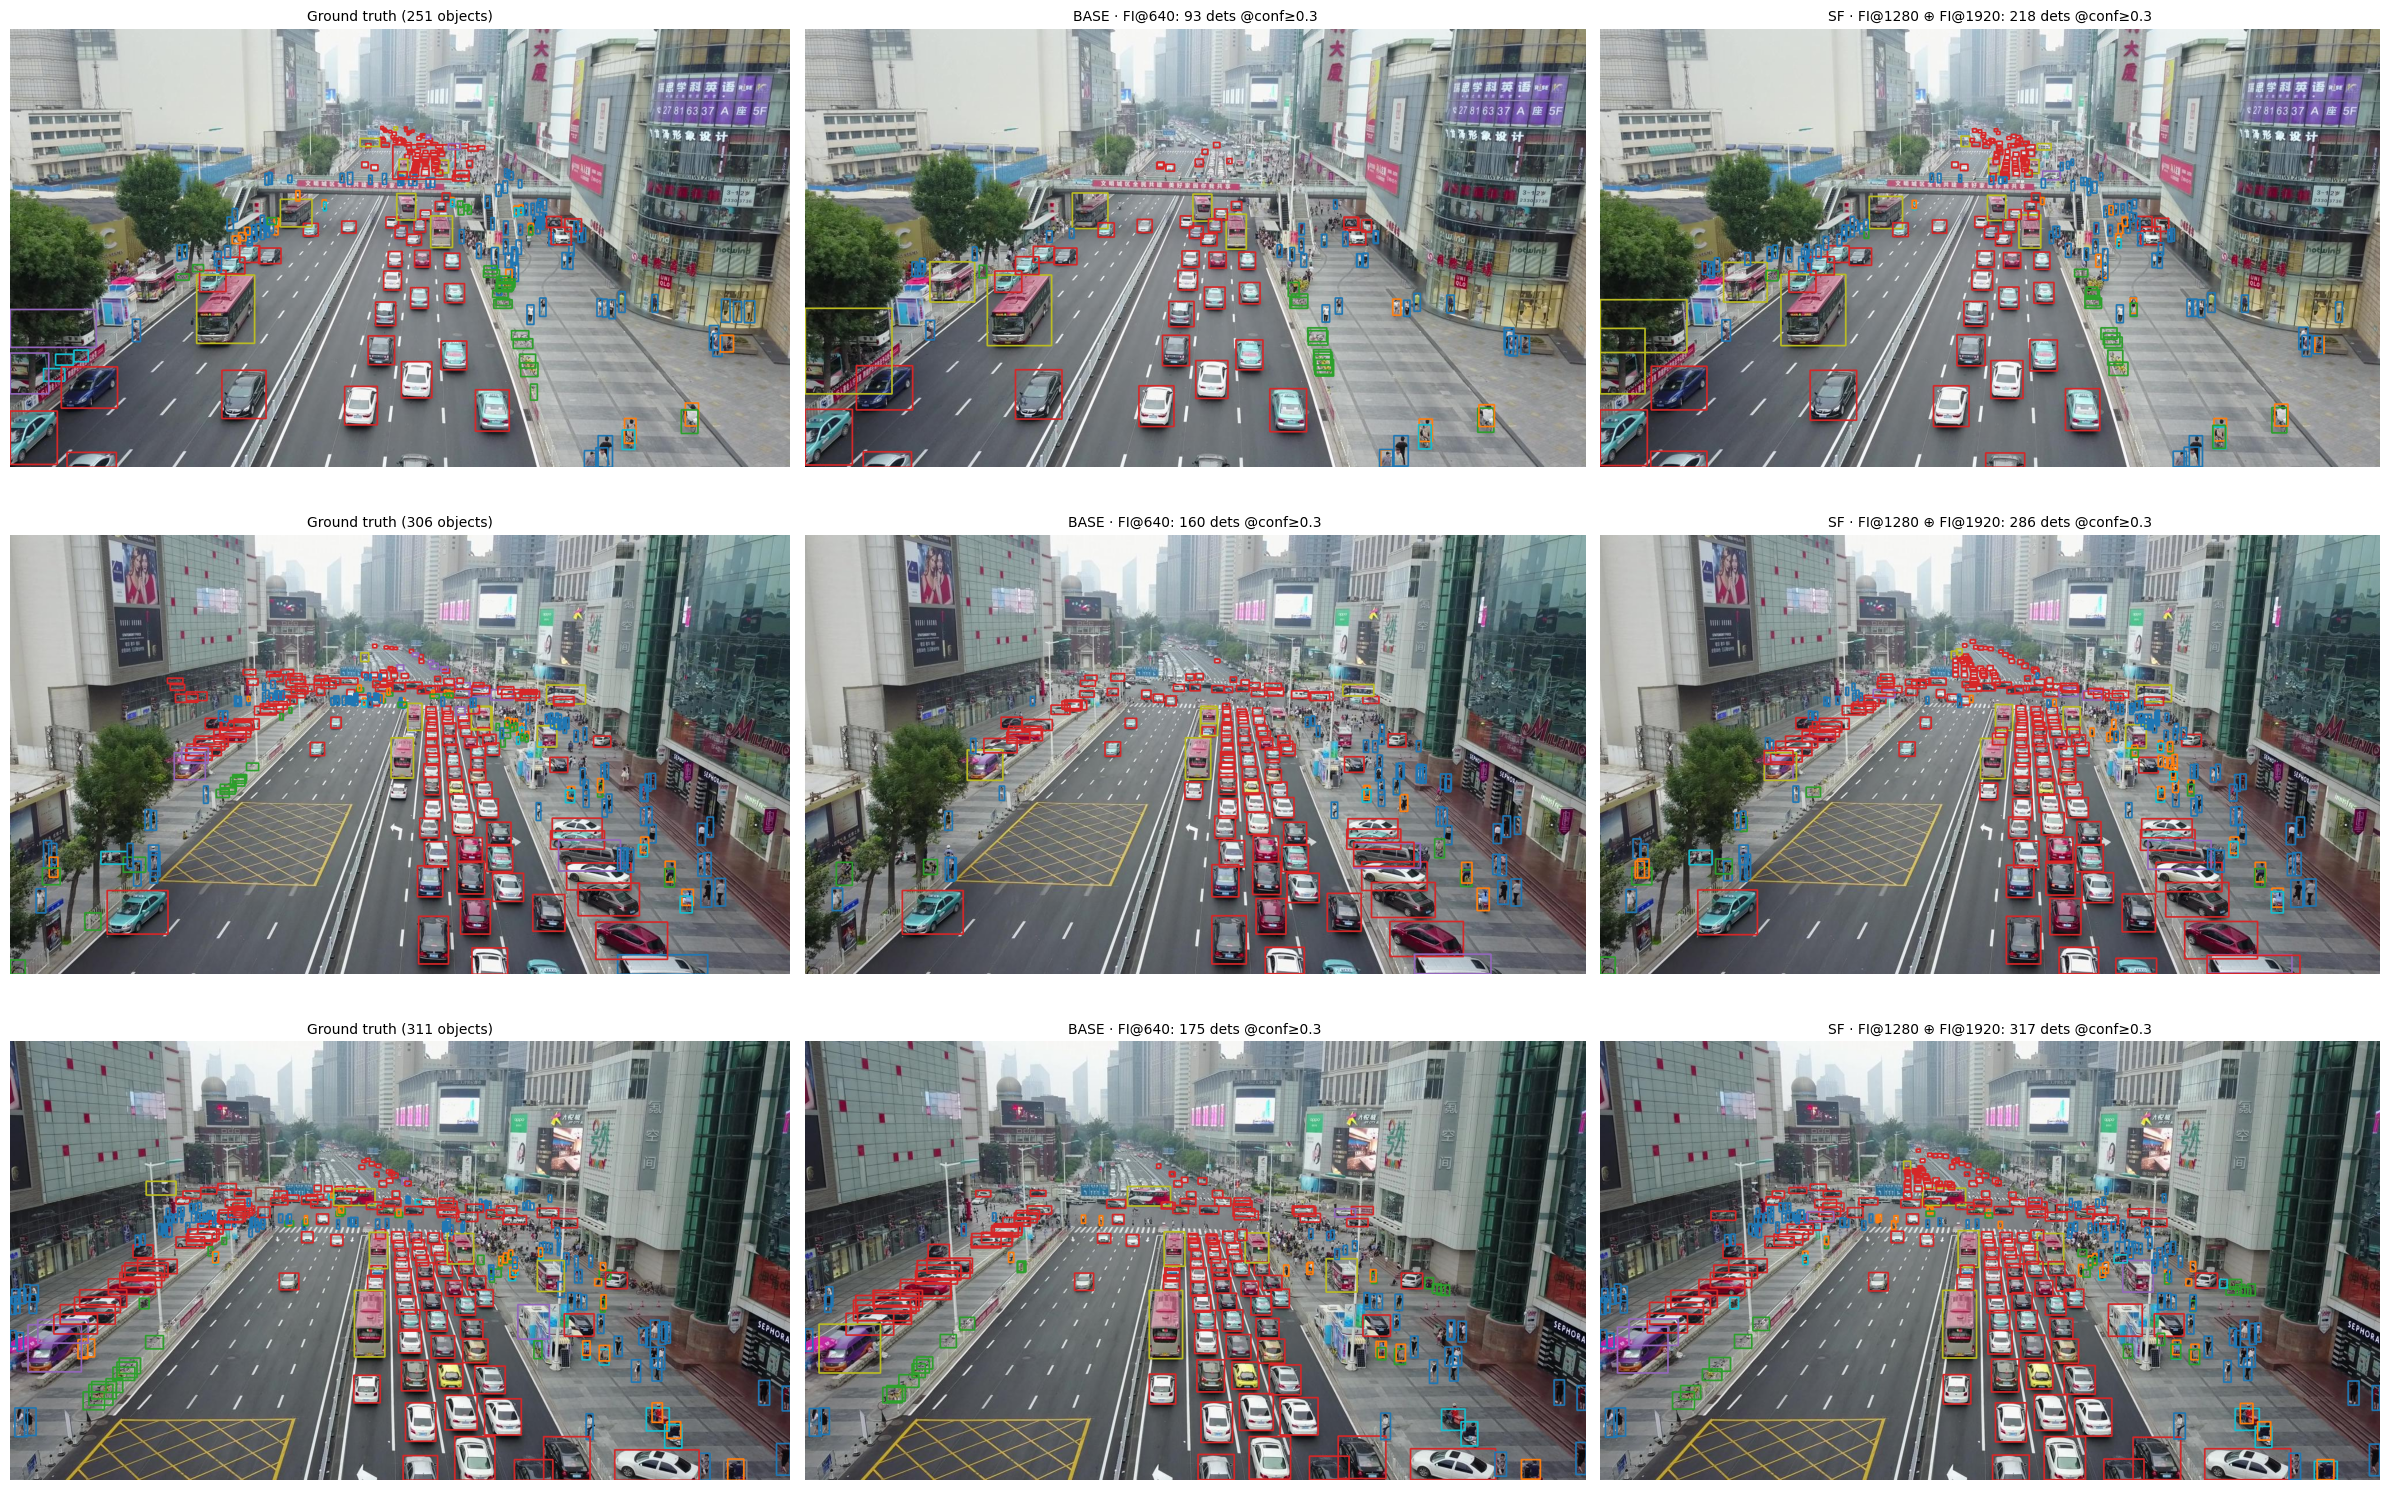

In [17]:
def draw(ax, r, boxes, title):
    im = cv2.cvtColor(cv2.imread(str(r["file"])), cv2.COLOR_BGR2RGB)
    for c, x, y, w, h in boxes:
        col = tuple(int(255 * v) for v in plt.cm.tab10(int(c) % 10)[:3])
        cv2.rectangle(im, (int(x), int(y)), (int(x + w), int(y + h)), col, 2)
    ax.imshow(im); ax.set_title(title, fontsize=10); ax.axis("off")

def dets_for(name, r, split="val"):
    a = PRED_CACHE[(name, split)]; a = a[(a[:, 0] == r["id"]) & (a[:, 6] >= VIS_CONF)]
    return [(c - 1, x, y, w, h) for _, c, x, y, w, h, _ in a]

def n_tiny(r): return int(((r["boxes"][:, 3] * r["boxes"][:, 4]) < 16 ** 2).sum()) if len(r["boxes"]) else 0
show = sorted(RECS["val"], key=n_tiny, reverse=True)[:3]
fig, axes = plt.subplots(len(show), 3, figsize=(24, 5.2 * len(show)))
axes = np.atleast_2d(axes)
for row, r in zip(axes, show):
    draw(row[0], r, r["boxes"], f"Ground truth ({len(r['boxes'])} objects)")
    d0, d1 = dets_for(REF_NAME, r), dets_for(BEST_NAME, r)
    draw(row[1], r, d0, f"{REF_NAME}: {len(d0)} dets @conf≥{VIS_CONF}")
    draw(row[2], r, d1, f"{BEST_NAME}: {len(d1)} dets @conf≥{VIS_CONF}")
plt.tight_layout(); plt.savefig(OUT / "qualitative.png", dpi=110); plt.show()

## 9 · Export the deployable detector

78 objects in 0000006_00159_d_0000001.jpg  (pipeline: SF · FI@1280 ⊕ FI@1920)


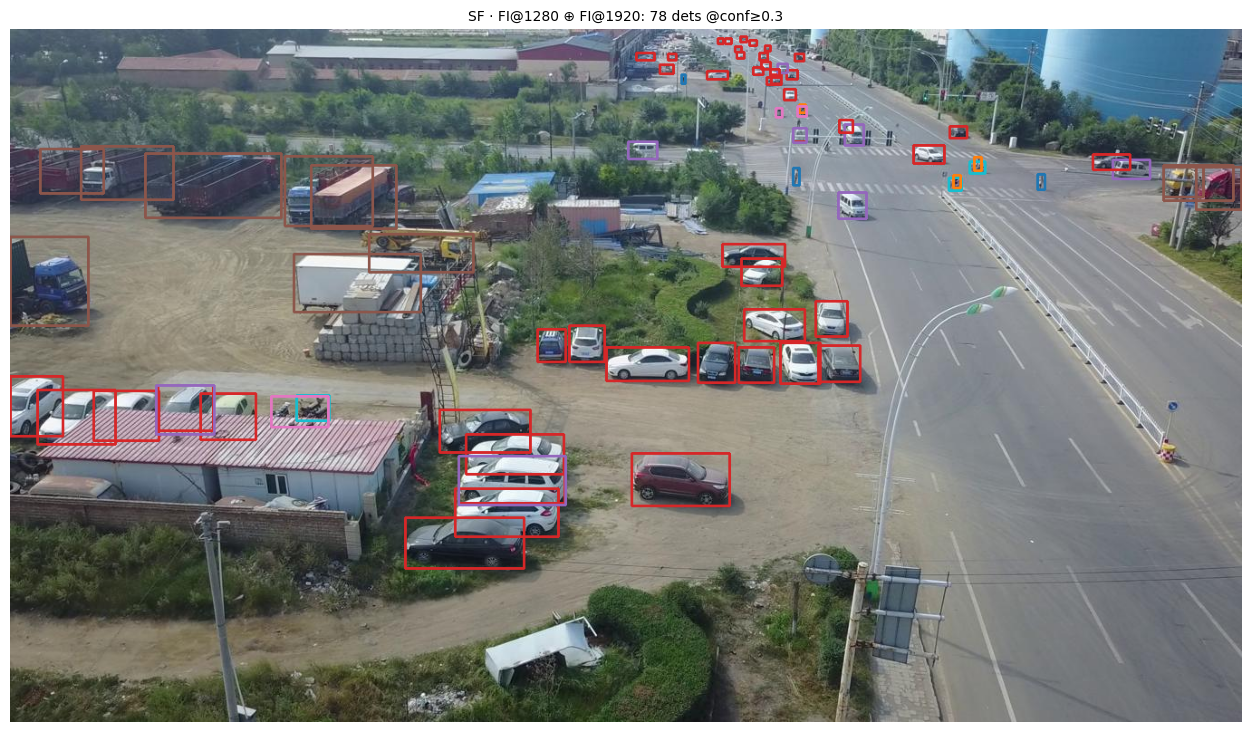

In [18]:
best_w = W[BEST_CFG["w"]]
shutil.copy(best_w, OUT / "yolo26_visdrone_best.pt")
def _pipeline(cfg):
    cfg = {k: v for k, v in cfg.items() if k not in ("name", "w")}
    if cfg["kind"] == "hybrid": cfg["parts"] = [_pipeline(CFG_BY_NAME[p]) for p in cfg["parts"]]
    return cfg
DEPLOY = dict(weights="yolo26_visdrone_best.pt", method=BEST_NAME, pipeline=_pipeline(BEST_CFG), classes=CLASSES,
              val=VAL.loc[BEST_NAME].to_dict(), testdev=TEST.loc[BEST_NAME].to_dict() if BEST_NAME in TEST.index else None, env=ENV)
json.dump(DEPLOY, open(OUT / "inference_config.json", "w"), indent=2, default=float)

def infer(image, pipe=DEPLOY["pipeline"], weights=best_w, conf=VIS_CONF):
    # Run the val-selected pipeline on one image path. Returns np.array rows [class_id, x, y, w, h, score] (original pixels).
    if pipe["kind"] == "full":
        b = _YOLO_CACHE.setdefault(str(weights), YOLO(str(weights))).predict(image, imgsz=pipe["imgsz"], conf=conf, max_det=MAX_DETS,
                                                                            device=DEVICE, verbose=False)[0].boxes
        xyxy = b.xyxy.cpu().numpy()
        return np.c_[b.cls.cpu().numpy(), xyxy[:, :2], xyxy[:, 2:] - xyxy[:, :2], b.conf.cpu().numpy()].astype(np.float32)
    if pipe["kind"] == "sahi":
        preds = run_sahi(sahi_model(weights, conf), image, **{k: v for k, v in pipe.items() if k != "kind"}).object_prediction_list
        return np.array([[p.category.id, p.bbox.minx, p.bbox.miny, p.bbox.maxx - p.bbox.minx, p.bbox.maxy - p.bbox.miny, p.score.value]
                         for p in preds], np.float32).reshape(-1, 6)
    parts = [np.c_[np.zeros(len(a)), a[:, 0] + 1, a[:, 1:]] for a in (infer(image, q, weights, conf) for q in pipe["parts"])]
    f = fuse_nms([x.astype(np.float32) for x in parts], pipe.get("iou", 0.5))
    return np.c_[f[:, 1] - 1, f[:, 2:]].astype(np.float32)

demo_r = RECS["test"][0]; demo = demo_r["file"]
res = infer(str(demo))
print(f"{len(res)} objects in {demo.name}  (pipeline: {BEST_NAME})")
fig, ax = plt.subplots(figsize=(16, 9)); draw(ax, demo_r, res[:, :5], f"{BEST_NAME}: {len(res)} dets @conf≥{VIS_CONF}")
plt.savefig(OUT / "demo_prediction.png", dpi=110, bbox_inches="tight"); plt.show()

In [19]:
# Summary for the write-up
summary = TEST[["AP", "AP50", "AP75", "AP_tiny", "AP_s", "AP_m", "AP_l", "AR500", "ms_per_img"]].copy()
summary[summary.columns[:-1]] *= 100
print(summary.round(2).to_string())
print(f"\nSelected on val: {BEST_NAME}")
print("Artifacts:", sorted(p.name for p in OUT.iterdir()))

                              AP   AP50   AP75  AP_tiny   AP_s   AP_m   AP_l  AR500  ms_per_img
method                                                                                         
BASE · FI@640              17.74  30.80  17.89     4.38   8.38  26.98  41.73  27.52       20.48
BASE · FI@1280             22.43  38.75  22.43     8.36  14.26  31.23  34.30  35.17       33.07
SF · FI@640                19.18  32.73  19.56     4.31   8.87  29.73  50.00  27.99       20.91
SF · FI@1280               26.84  44.77  27.27     9.91  16.44  38.30  50.89  37.97       33.23
SF · SAHI + FI  [default]  26.64  45.27  27.01     9.51  16.29  38.01  49.50  39.37      130.70
SF · FI@1280 ⊕ FI@1920     28.54  47.90  28.86    11.21  18.31  39.55  50.92  40.68      103.31

Selected on val: SF · FI@1280 ⊕ FI@1920
Artifacts: ['ablation_val.csv', 'ablation_val.png', 'demo_prediction.png', 'eda.png', 'environment.json', 'inference_config.json', 'qualitative.png', 'results_testdev.csv', 'testdev_breakdown

## 10 · Discussion, limitations & next steps

**v1 findings (test-dev, YOLO26s, 40 epochs).** Slice-aided fine-tuning was the largest single win (+4.4 AP at FI@1280 vs. the
full-image baseline), and inference resolution the second (+7.7 AP from 640 → 1280 for SF). SAHI *inference* under-performed because
(i) GREEDY-NMM/IoS at a 0.01 score floor fuses low-score boxes into oversized unions — catastrophic for AP75 in dense crowds — and
(ii) SAHI's built-in full-image pass runs at the slice network size (640), the model's weakest operating point. v2 isolates both effects.

**Reading the v2 tables.** Compare `SF · SAHI + FI [v1 default]` vs `[default]` (merge only), `SF · SAHI xxx (no FI)` vs `SF · FI@1280`
(slicing vs. resolution), and the `⊕` rows (do slices add information on top of a high-resolution full pass?). Slices should help mostly in the
*tiny* bucket; the full-image pass keeps *medium/large* objects that slices cut in half.

**Caveats (state these in any paper/report):**
* `force_postprocess_type=True`: the merge we request is the merge that runs (SAHI would otherwise swap to NMS when the score floor < 0.1).
* Hybrid latency = sum of the two passes run sequentially; both could share one batched forward pass in deployment.
* `EVAL_CONF=0.01` is used for every method (instead of 0.001) to keep sliced merging tractable; AP is slightly under-estimated for all rows equally.
* Many val rows → mild optimistic bias in the *val* number of the selected row; the test-dev number is unbiased (evaluated once).
* Numbers are COCO-style AP with VisDrone ignore regions — comparable to, but not bit-identical with, the official MATLAB VisDrone toolkit.
* Latency is end-to-end Python wall-clock on the Kaggle GPU (FP32, includes JPEG decode); TensorRT would shrink every row.
* One seed. For publication, repeat training with ≥3 seeds and report mean ± std.

**Ways to push accuracy further:** train the full-image model at `imgsz=1280` (resolution is the cheapest lever here) · `PROFILE="max_accuracy"`
(YOLO26l, 80 epochs) · weighted-box-fusion instead of NMS · test-time flip augmentation · pseudo-label test-challenge.

### References
1. F. C. Akyon, S. O. Altinuc, A. Temizel. *Slicing Aided Hyper Inference and Fine-tuning for Small Object Detection.* ICIP 2022. arXiv:2202.06934
2. P. Zhu et al. *Detection and Tracking Meet Drones Challenge.* IEEE TPAMI 2021 (VisDrone).
3. Ultralytics. *YOLO26* documentation, 2026 — https://docs.ultralytics.com/models/yolo26
4. T.-Y. Lin et al. *Microsoft COCO: Common Objects in Context.* ECCV 2014 (evaluation protocol).